# 1. Build a mushroom model

**Question:** Is this mushroom poisonous?

We have 8,124 mushrooms described in a field guide: what they look and smell like, and whether they are edible. We teach a model the pattern, check honestly how good it is, and save it so a FastAPI app can answer the question (see `app/main.py`).

> A teaching set, not a foraging tool. Never eat a wild mushroom because a model said so.

The plan:

1. Load the data and translate the one-letter codes
2. Look at it
3. Split into train and test
4. A baseline, and the cost of each mistake
5. One feature at a time
6. Compare two models with cross-validation
7. Choose a *safe* decision threshold
8. Test once
9. Without the nose: drop `odor`
10. Predict, and ask "what if"
11. Save the model

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, recall_score
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

import train_mushroom
from app.codes import FEATURES

## 1. Load the data and translate the codes

Every value in the CSV is a single letter: `p` can mean *pungent* (odor), *pink* (colour) or *pendant* (ring type). `app/codes.py` maps each letter to a word, per column. `train_mushroom.load_data` does the translation, so the model and the API both use words.

In [2]:
raw = pd.read_csv(ROOT / 'data' / 'mushrooms.csv')
print(raw.shape)
raw.head(3)

(8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m


In [3]:
df = train_mushroom.load_data(ROOT / 'data' / 'mushrooms.csv')
df.head(3)

,poisonous,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_above_ring,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,1,convex,smooth,brown,yes,pungent,free,close,narrow,black,...,smooth,smooth,white,white,white,one,pendant,black,scattered,urban
1,0,convex,smooth,yellow,yes,almond,free,close,broad,black,...,smooth,smooth,white,white,white,one,pendant,brown,numerous,grasses
2,0,bell,smooth,white,yes,anise,free,close,broad,brown,...,smooth,smooth,white,white,white,one,pendant,brown,numerous,meadows


In [4]:
# veil-type has one value for all 8,124 mushrooms: useless, so it was dropped.
print(raw['veil-type'].value_counts())
# stalk-root has '?' for 2,480 rows: kept as its own value, 'missing'.
df['stalk_root'].value_counts()

veil-type
p    8124
Name: count, dtype: int64


stalk_root
bulbous    3776
missing    2480
equal      1120
club        556
rooted      192
Name: count, dtype: int64

## 2. Look at it

The two classes are almost balanced: no accuracy paradox here.

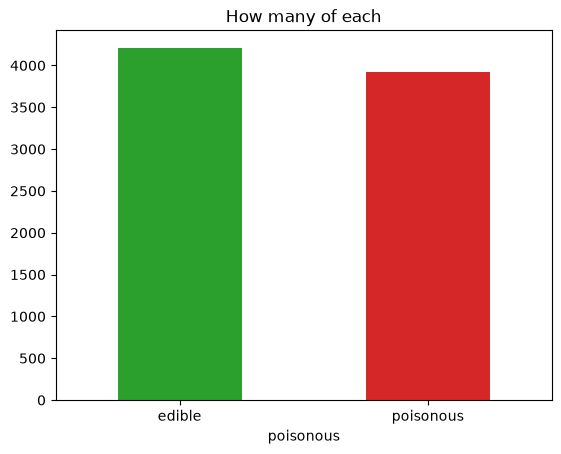

In [5]:
df['poisonous'].map({0: 'edible', 1: 'poisonous'}).value_counts().plot.bar(
    color=['tab:green', 'tab:red'], rot=0, title='How many of each')
plt.show()

Now one feature against the target. Look at `odor`: almost every smell belongs to one class only. Only `none` is mixed.

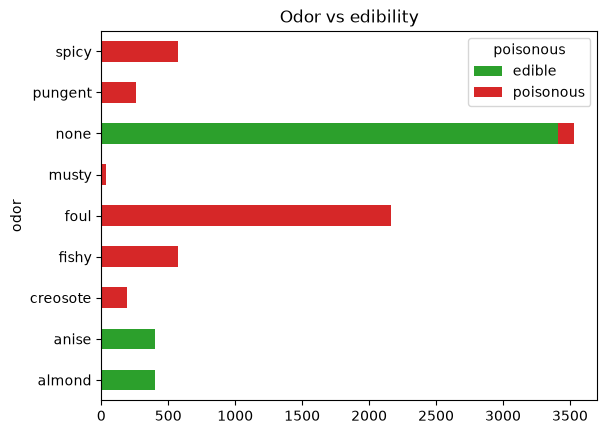

In [6]:
pd.crosstab(df['odor'], df['poisonous'].map({0: 'edible', 1: 'poisonous'})).plot.barh(
    stacked=True, color=['tab:green', 'tab:red'], title='Odor vs edibility')
plt.show()

In [7]:
pd.crosstab(df['spore_print_color'], df['poisonous'].map({0: 'edible', 1: 'poisonous'}))

poisonous,edible,poisonous
spore_print_color,,
black,1648,224
brown,1744,224
buff,48,0
chocolate,48,1584
green,0,72
orange,48,0
purple,48,0
white,576,1812
yellow,48,0


## 3. Split: train on 80%, keep 20% aside for the final test

In [8]:
X, y = df[FEATURES], df['poisonous']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
len(X_train), len(X_test)

(6499, 1625)

## 4. A baseline, and the cost of each mistake

Always answering *edible* is right half the time. But the two mistakes are not equal:

- **Poisonous called edible** (a false negative): someone gets ill, or worse.
- **Edible called poisonous** (a false positive): someone skips a meal.

So the number to watch is **recall on poisonous**: the share of poisonous mushrooms we catch. We want it at 100%.

In [9]:
baseline = np.zeros(len(y_test), dtype=int)
print(f'accuracy {accuracy_score(y_test, baseline):.1%}, '
      f'recall on poisonous {recall_score(y_test, baseline):.0%}')

accuracy 51.8%, recall on poisonous 0%


## 5. One feature at a time

Models need numbers, so `OneHotEncoder` turns each word into its own 0/1 column (`odor=foul`, `odor=none`...). How well does each feature do on its own?

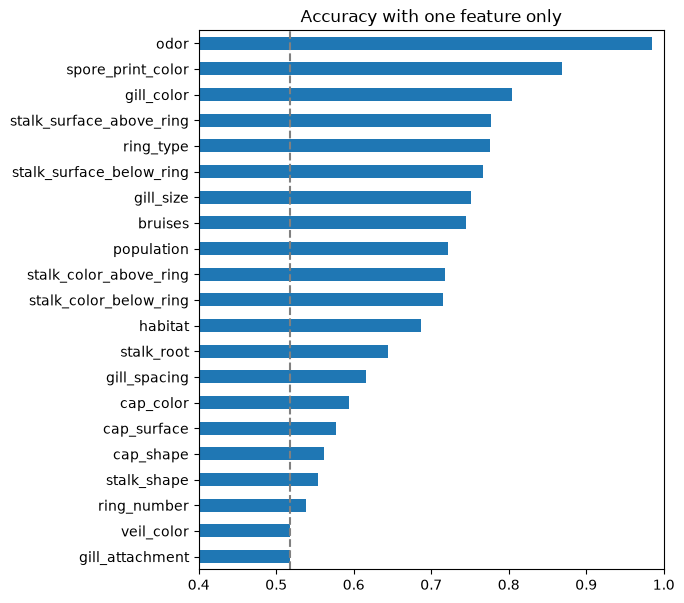

In [10]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
one = make_pipeline(OneHotEncoder(handle_unknown='ignore'), LogisticRegression(max_iter=1000))
alone = pd.Series({f: cross_val_score(one, X_train[[f]], y_train, cv=folds).mean()
                   for f in FEATURES}).sort_values()
alone.plot.barh(figsize=(6, 7), title='Accuracy with one feature only', xlim=(0.4, 1))
plt.axvline(0.518, color='gray', linestyle='--')  # the baseline
plt.show()

## 6. Compare two models with cross-validation

Both use all 21 features. Cross-validation scores them on the training data only: the test set stays untouched until the very end.

In [11]:
candidates = {
    'logistic regression': make_pipeline(
        OneHotEncoder(handle_unknown='ignore'), LogisticRegression(max_iter=1000)),
    'random forest': make_pipeline(
        OneHotEncoder(handle_unknown='ignore'),
        RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
}
for name, model in candidates.items():
    auc = cross_val_score(model, X_train, y_train, cv=folds, scoring='roc_auc')
    print(f'{name:<20} ROC AUC {auc.mean():.4f} (+/- {auc.std():.4f})')
model = candidates['random forest']

logistic regression  ROC AUC 1.0000 (+/- 0.0000)


random forest        ROC AUC 1.0000 (+/- 0.0000)


Both are perfect. That is rare, and worth being suspicious about: is something leaking? Here no: the field guide's descriptions really do separate the species. Real data (photos, a beginner's description) would be much harder.

## 7. Choose a *safe* decision threshold

The model gives a probability. Where we cut it is a business decision, here a safety one: we keep the thresholds that flag **every** poisonous mushroom in cross-validation, then the one with the fewest false alarms (on a tie, the lowest: the most cautious).

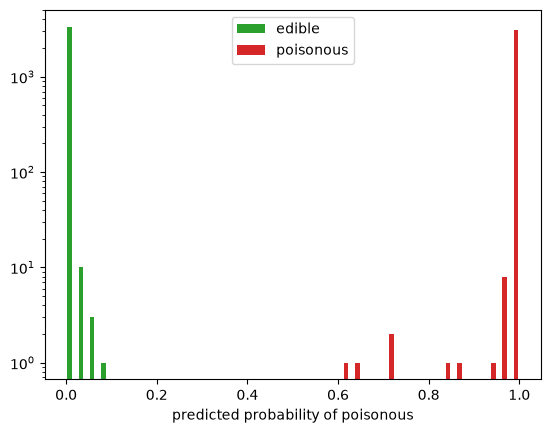

In [12]:
proba_cv = cross_val_predict(model, X_train, y_train, cv=folds, method='predict_proba')[:, 1]
plt.hist([proba_cv[y_train == 0], proba_cv[y_train == 1]], bins=40,
         color=['tab:green', 'tab:red'], label=['edible', 'poisonous'])
plt.xlabel('predicted probability of poisonous')
plt.legend()
plt.yscale('log')
plt.show()

In [13]:
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)
safe = [t for t in thresholds if recall_score(y_train, proba_cv >= t) == 1.0]
alarms = {t: int(((proba_cv >= t) & (y_train == 0)).sum()) for t in safe}
threshold = float(min(safe, key=lambda t: (alarms[t], t)))
print(f'safe thresholds: {safe[0]} to {safe[-1]}; chosen: {threshold}')

safe thresholds: 0.01 to 0.61; chosen: 0.09


## 8. Test once

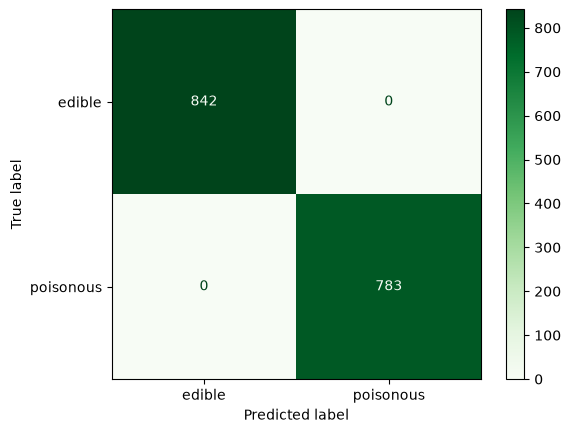

In [14]:
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
predicted = (proba >= threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted, display_labels=['edible', 'poisonous'], cmap='Greens')
plt.show()

## 9. Without the nose: drop `odor`

Permutation importance (used for churn) says almost nothing here: hide one feature and the others make up for it. Dropping the strongest feature outright shows that redundancy directly.

In [15]:
no_odor = [f for f in FEATURES if f != 'odor']
acc = cross_val_score(clone(model), X_train[no_odor], y_train, cv=folds).mean()
print(f'without odor: {acc:.2%} accuracy')

without odor: 100.00% accuracy


## 10. Predict, and ask "what if"

The second mushroom in the file is edible. What if it smelled foul instead of almond?

In [16]:
mushroom = df.loc[[1], FEATURES]
what_if = mushroom.assign(odor='foul')
for label, row in [('as found (almond)', mushroom), ('what if: foul', what_if)]:
    p = model.predict_proba(row)[0, 1]
    print(f'{label:<20} P(poisonous) = {p:.2f} -> '
          f"{'poisonous' if p >= threshold else 'edible'}")

as found (almond)    P(poisonous) = 0.00 -> edible
what if: foul        P(poisonous) = 0.31 -> poisonous


## 11. Save the model

`train_mushroom.train()` runs these same steps and saves a *bundle*: the model plus the feature order, the threshold, the scores and the scikit-learn version. The API loads it.

In [17]:
bundle = train_mushroom.train(ROOT / 'data' / 'mushrooms.csv', ROOT / 'models', verbose=False)
{k: v for k, v in bundle.items() if k != 'model'}

{'algorithm': 'random forest',
 'features': ['cap_shape',
  'cap_surface',
  'cap_color',
  'bruises',
  'odor',
  'gill_attachment',
  'gill_spacing',
  'gill_size',
  'gill_color',
  'stalk_shape',
  'stalk_root',
  'stalk_surface_above_ring',
  'stalk_surface_below_ring',
  'stalk_color_above_ring',
  'stalk_color_below_ring',
  'veil_color',
  'ring_number',
  'ring_type',
  'spore_print_color',
  'population',
  'habitat'],
 'threshold': 0.09,
 'metrics': {'roc_auc': 1.0,
  'accuracy': 1.0,
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'poisonous_missed': 0,
  'false_alarms': 0},
 'trained_at': '2026-10-17T04:14:09+00:00',
 'sklearn_version': '1.9.1'}

## Exercises

1. Train on only the features you can **see** (drop `odor`). Which threshold is safe now?
2. How few features do you need for a perfect cross-validated score? Try the top 3 from step 5.
3. Replace the random forest with a `DecisionTreeClassifier(max_depth=4)` and print the rules with `sklearn.tree.export_text`. Could a person follow them?